# Pick 10 stocks each industry, from 10 industries. From that 100 stocks, pick 10 with the highest growth in the last month, buy and hold it for the next month. Rebalancing monthly, 10% each stock.


In [27]:
!pip install yfinance

In [28]:
import os
import warnings
import numpy as np
import pandas as pd
from scipy.stats import gmean
import yfinance as yf
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from datetime import datetime, timedelta, date, time
warnings.filterwarnings('ignore')

In [29]:
tickers = ['SPY',"NVDA", "MSFT", "AAPL", "AMZN", "GOOGL", "META", "AVGO", "BRK-B", "TSLA", "JPM",
    "WMT", "LLY", "V", "ORCL", "NFLX", "MA", "XOM", "COST", "PG", "JNJ",
    "HD", "BAC", "ABBV", "PLTR", "KO", "UNH", "PM", "TMUS", "CSCO", "WFC",
    "CRM", "GE", "AMD", "DOW", "NKE", "MCD", "PFE", "TXN", "MRK", "IBM",
    "ADBE", "INTC", "T", "UPS", "AMGN", "QCOM", "VZ", "SO", "BMY", "HON",
    "LIN", "CVX", "CAT", "GS", "NEE", "LOW", "SPGI", "MS", "BLK", "RTX",
    "NOW", "SCHW", "BA", "ISRG", "CI", "MDT", "DE", "ELV", "AXP", "INTU",
    "ADP", "CB", "TJX", "PYPL", "C", "ZTS", "PGR", "DUK", "MMC", "LMT",
    "VRTX", "SYK", "TMO", "BDX", "MO", "ADI", "REGN", "BKNG", "ICE", "ABNB",
    "FDX", "GM", "NSC", "FIS", "HUM", "CL", "GILD", "WM", "EW", "AON",
    "ROST", "DHR", "PNC", "ETN", "ITW", "SHW", "CSX", "MNST", "TRV", "EMR",
    "AEP", "ALL", "GD", "PSX", "HCA", "MCO", "MAR", "APD", "EOG", "LRCX",
    "KLAC", "PCAR", "CDNS", "MCK", "CTAS", "ORLY", "AFL", "STZ", "ANET", "FTNT",
    "KHC", "PAYX", "PH", "MTD", "CTSH", "TGT", "AZO", "IDXX", "TT", "SRE",
    "WELL", "DLR", "F", "CME", "PXD", "ED", "MRNA", "CMI", "NEM", "HSY",
    "WBA", "TEL", "ODFL", "BIIB", "HPQ", "CARR", "AME", "COF", "HES", "D",
    "AIG", "A", "MSI", "EXC", "RSG", "YUM", "HIG", "O", "XEL", "TSCO",
    "CHD", "DFS", "KEYS", "FAST", "EFX", "TDG", "ACN", "BKR", "CEG", "GPN",
    "KMB", "AVB", "VRSK", "FRC", "CDW", "HLT", "CMS", "ROL", "NUE", "ATO",
    "VLO", "ZBH", "QRVO", "IP", "MTB", "FTV", "ULTA", "MLM", "LH", "HOLX",
    "INCY", "WAT", "XYL", "LUV", "PKI", "NVR", "SJM", "PPG", "NDAQ", "DRI"]
# List of companies
data = yf.download(tickers, start='2015-01-01', end='2025-08-01', interval="1mo")['Close'].pct_change()
data.set_index(pd.to_datetime(data.index), inplace=True)
data

[*********************100%***********************]  211 of 211 completed
ERROR:yfinance:
4 Failed downloads:
ERROR:yfinance:['FRC']: YFPricesMissingError('possibly delisted; no price data found  (1mo 2015-01-01 -> 2025-08-01)')
ERROR:yfinance:['PXD', 'PKI', 'DFS']: YFTzMissingError('possibly delisted; no timezone found')


Ticker,A,AAPL,ABBV,ABNB,ACN,ADBE,ADI,ADP,AEP,AFL,...,WELL,WFC,WM,WMT,XEL,XOM,XYL,YUM,ZBH,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-02-01,0.120290,0.096449,0.010012,NaN,0.071403,0.127905,0.123393,0.076457,-0.083267,0.090574,...,-0.059060,0.055277,0.059304,-0.012356,-0.059952,0.012812,0.046921,0.128536,0.073952,0.080662
2015-03-01,-0.015636,-0.027549,-0.032397,NaN,0.040653,-0.065234,0.083458,-0.036020,-0.014736,0.034801,...,0.013485,-0.000574,-0.004589,-0.020016,-0.013322,-0.032756,-0.015148,-0.029466,-0.023839,0.004340
2015-04-01,-0.001880,0.005786,0.104544,NaN,-0.011101,0.028672,-0.018413,-0.007131,0.011022,-0.015154,...,-0.069027,0.012867,-0.080238,-0.045365,-0.016721,0.027882,0.057110,0.091972,-0.063624,-0.040398
2015-05-01,-0.004351,0.040991,0.038390,NaN,0.047676,0.039837,0.098965,0.011474,-0.010199,-0.013008,...,-0.024438,0.015608,0.002423,-0.048430,0.004129,-0.024837,-0.012155,0.053797,0.038693,0.122452
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-03-01,-0.085522,-0.080490,0.002344,-0.139771,-0.104620,-0.125479,-0.123403,-0.030617,0.040001,0.021394,...,0.002505,-0.078851,-0.005456,-0.109725,-0.018169,0.077821,-0.084495,0.011087,0.084931,-0.015487
2025-04-01,-0.080185,-0.043353,-0.068824,0.020593,-0.041309,-0.022293,-0.029265,-0.010893,-0.008511,-0.022574,...,-0.004047,-0.010865,0.011731,0.110799,0.007088,-0.111830,0.009292,-0.043976,-0.087553,-0.050106
2025-05-01,0.042358,-0.054824,-0.037263,0.058071,0.064319,0.106966,0.097784,0.082934,-0.044766,-0.047295,...,0.011076,0.053091,0.032611,0.015116,-0.008487,-0.031525,0.045368,-0.043207,-0.105580,0.081835


In [30]:
if 'monthly_pnl' in data.columns:
    data = data.drop('monthly_pnl', axis=1)

current = []
total_pnls = [0,0]
for i in range(2, len(data)):
    last_month = data.index[i-1]
    current_month = data.index[i]

# for month in data.index:
    top_10_monthly = data.loc[last_month].dropna().sort_values(ascending=False).head(10)
    # print(f"Top 10 tickers for {last_month}: {top_10_monthly.index.tolist()}")
    for top_ticker in top_10_monthly.index:
        current.append(data.loc[current_month, top_ticker])
    total_pnls.append(np.mean(current))
    current = []

data['monthly_pnl'] = total_pnls
# data['monthly_pnl'] = data['temp_monthly_pnl'].shift(1)
# data = data.drop('temp_monthly_pnl', axis=1)
data = data.fillna(0)
data

Ticker,A,AAPL,ABBV,ABNB,ACN,ADBE,ADI,ADP,AEP,AFL,...,WFC,WM,WMT,XEL,XOM,XYL,YUM,ZBH,ZTS,monthly_pnl
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-01,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2015-02-01,0.120290,0.096449,0.010012,0.000000,0.071403,0.127905,0.123393,0.076457,-0.083267,0.090574,...,0.055277,0.059304,-0.012356,-0.059952,0.012812,0.046921,0.128536,0.073952,0.080662,0.000000
2015-03-01,-0.015636,-0.027549,-0.032397,0.000000,0.040653,-0.065234,0.083458,-0.036020,-0.014736,0.034801,...,-0.000574,-0.004589,-0.020016,-0.013322,-0.032756,-0.015148,-0.029466,-0.023839,0.004340,-0.028457
2015-04-01,-0.001880,0.005786,0.104544,0.000000,-0.011101,0.028672,-0.018413,-0.007131,0.011022,-0.015154,...,0.012867,-0.080238,-0.045365,-0.016721,0.027882,0.057110,0.091972,-0.063624,-0.040398,-0.043700
2015-05-01,-0.004351,0.040991,0.038390,0.000000,0.047676,0.039837,0.098965,0.011474,-0.010199,-0.013008,...,0.015608,0.002423,-0.048430,0.004129,-0.024837,-0.012155,0.053797,0.038693,0.122452,0.024658
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-03-01,-0.085522,-0.080490,0.002344,-0.139771,-0.104620,-0.125479,-0.123403,-0.030617,0.040001,0.021394,...,-0.078851,-0.005456,-0.109725,-0.018169,0.077821,-0.084495,0.011087,0.084931,-0.015487,-0.010209
2025-04-01,-0.080185,-0.043353,-0.068824,0.020593,-0.041309,-0.022293,-0.029265,-0.010893,-0.008511,-0.022574,...,-0.010865,0.011731,0.110799,0.007088,-0.111830,0.009292,-0.043976,-0.087553,-0.050106,-0.040525
2025-05-01,0.042358,-0.054824,-0.037263,0.058071,0.064319,0.106966,0.097784,0.082934,-0.044766,-0.047295,...,0.053091,0.032611,0.015116,-0.008487,-0.031525,0.045368,-0.043207,-0.105580,0.081835,0.111842


In [31]:
sharpe_ratio = np.mean(total_pnls) / np.std(total_pnls)
print(f"Sharpe Ratio: {sharpe_ratio}")

Sharpe Ratio: 0.31002405725064686


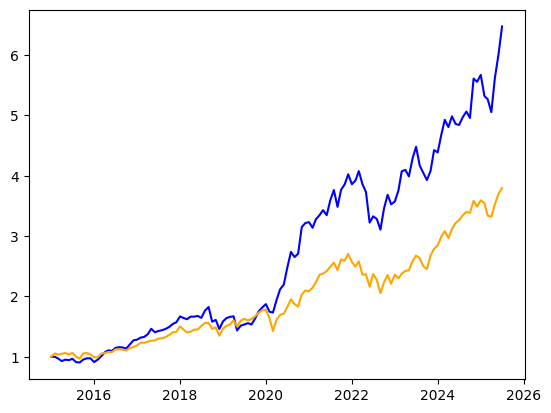

In [32]:
dates = data.index
spy = data['SPY']
# Plot profit
# plt.plot(dates, np.cumsum(total_pnls))
#plt.plot(dates,np.cumprod(1+np.array(total_pnls)),'-o')
plt.plot(dates,np.cumprod(1+np.array(total_pnls)),color = 'blue')
plt.plot(dates,np.cumprod(1+np.array(spy)),color = 'orange')
#plt.plot(dates, np.cumsum(total_pnls))